In [ ]:
!pip install numpy scipy matplotlib scikit-learn tensorflow


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf

print("Bibliotecas cargadas correctamente")
print("TensorFlow:", tf.__version__)


Bibliotecas cargadas correctamente
TensorFlow: 2.21.0


In [ ]:
# Parámetros de las señales

frecuencia_muestreo = 8000
frecuencia_portadora = 1000
tasa_simbolos = 1000

muestras_simbolo = int(
    frecuencia_muestreo / tasa_simbolos
)

numero_simbolos = 16

total_muestras = (
    muestras_simbolo * numero_simbolos
)

print("Frecuencia de muestreo:", frecuencia_muestreo)
print("Frecuencia portadora:", frecuencia_portadora)
print("Tasa de símbolos:", tasa_simbolos)
print("Muestras por señal:", total_muestras)

Frecuencia de muestreo: 8000
Frecuencia portadora: 1000
Tasa de símbolos: 1000
Muestras por señal: 128


In [ ]:
def generar_ASK():
    bits = np.random.randint(0, 2, numero_simbolos)

    amplitudes = np.where(bits == 0, 0.3, 1.0)

    amplitudes = np.repeat(amplitudes, muestras_simbolo)

    t = np.arange(total_muestras) / frecuencia_muestreo

    senal = amplitudes * np.cos(
        2 * np.pi * frecuencia_portadora * t
    )

    return senal.astype(np.float32)

In [ ]:
def generar_FSK():
    bits = np.random.randint(0, 2, numero_simbolos)

    frecuencias = np.where(bits == 0, 800, 1200)

    frecuencias = np.repeat(frecuencias, muestras_simbolo)

    t = np.arange(total_muestras) / frecuencia_muestreo

    fase = np.zeros(total_muestras)

    fase[0] = 0

    for i in range(1, total_muestras):
        fase[i] = fase[i-1] + (
            2 * np.pi * frecuencias[i] / frecuencia_muestreo
        )

    senal = np.cos(fase)

    return senal.astype(np.float32)

In [ ]:
def generar_PSK():
    bits = np.random.randint(0, 2, numero_simbolos)

    fases = np.where(bits == 0, 0, np.pi)

    fases = np.repeat(fases, muestras_simbolo)

    t = np.arange(total_muestras) / frecuencia_muestreo

    senal = np.cos(
        2 * np.pi * frecuencia_portadora * t + fases
    )

    return senal.astype(np.float32)

In [ ]:
def generar_QAM():
    simbolos = np.random.randint(0, 16, numero_simbolos)

    niveles = np.array([-3, -1, 1, 3])

    I = niveles[simbolos // 4]
    Q = niveles[simbolos % 4]

    I = np.repeat(I, muestras_simbolo) / np.sqrt(10)
    Q = np.repeat(Q, muestras_simbolo) / np.sqrt(10)

    t = np.arange(total_muestras) / frecuencia_muestreo

    portadora_I = np.cos(
        2 * np.pi * frecuencia_portadora * t
    )

    portadora_Q = np.sin(
        2 * np.pi * frecuencia_portadora * t
    )

    senal = I * portadora_I - Q * portadora_Q

    return senal.astype(np.float32)

In [ ]:
# Generar una señal de cada tipo

senal_ask = generar_ASK()
senal_fsk = generar_FSK()
senal_psk = generar_PSK()
senal_qam = generar_QAM()

print("ASK:", senal_ask.shape)
print("FSK:", senal_fsk.shape)
print("PSK:", senal_psk.shape)
print("QAM:", senal_qam.shape)

print("\n¡Los cuatro generadores funcionan correctamente!")

ASK: (128,)
FSK: (128,)
PSK: (128,)
QAM: (128,)

¡Los cuatro generadores funcionan correctamente!


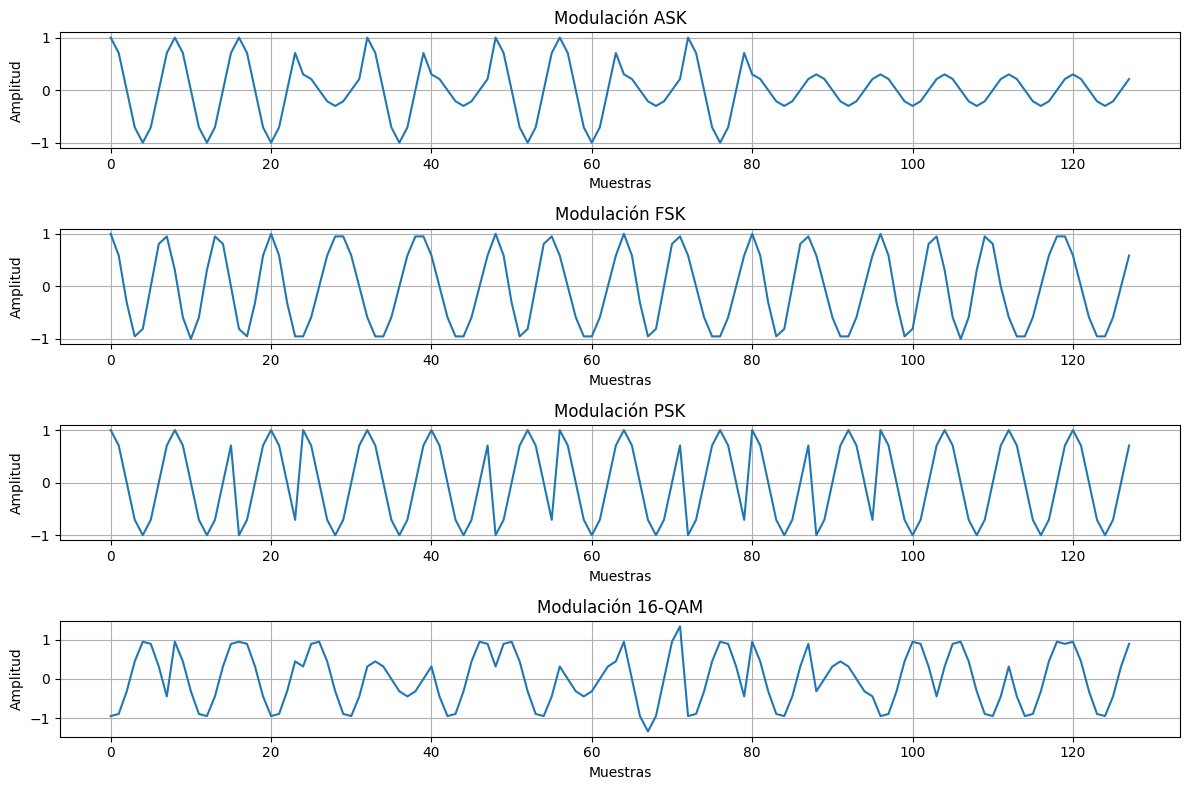

In [ ]:
plt.figure(figsize=(12, 8))

senales = [
    (senal_ask, "Modulación ASK"),
    (senal_fsk, "Modulación FSK"),
    (senal_psk, "Modulación PSK"),
    (senal_qam, "Modulación 16-QAM")
]

for i, (senal, titulo) in enumerate(senales):

    plt.subplot(4, 1, i + 1)

    plt.plot(senal)

    plt.title(titulo)
    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")

    plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
def agregar_ruido_AWGN(senal, snr_db):

    potencia_senal = np.mean(senal ** 2)

    snr_lineal = 10 ** (snr_db / 10)

    potencia_ruido = potencia_senal / snr_lineal

    ruido = np.random.normal(
        0,
        np.sqrt(potencia_ruido),
        len(senal)
    )

    senal_ruidosa = senal + ruido

    return senal_ruidosa.astype(np.float32)

In [ ]:
# Número de señales por modulación
muestras_por_modulacion = 1000

# Niveles de ruido que utilizaremos
niveles_snr = [-5, 0, 5, 10, 15, 20]

# Almacenar señales y etiquetas
datos = []
etiquetas = []
niveles_utilizados = []

# Generadores de señales
generadores = {
    "ASK": generar_ASK,
    "FSK": generar_FSK,
    "PSK": generar_PSK,
    "QAM": generar_QAM
}

# Generar las señales
for nombre, generador in generadores.items():

    for i in range(muestras_por_modulacion):

        # Generar señal original
        senal = generador()

        # Seleccionar un nivel de ruido aleatorio
        snr = np.random.choice(niveles_snr)

        # Agregar ruido
        senal_ruidosa = agregar_ruido_AWGN(
            senal, snr
        )

        # Guardar señal y etiqueta
        datos.append(senal_ruidosa)
        etiquetas.append(nombre)
        niveles_utilizados.append(snr)

# Convertir listas en arreglos NumPy
X = np.array(datos, dtype=np.float32)
y = np.array(etiquetas)
snr_datos = np.array(niveles_utilizados)

print("¡Conjunto de datos generado correctamente!")
print("Total de señales:", len(X))
print("Forma de los datos:", X.shape)
print("Total de etiquetas:", len(y))

¡Conjunto de datos generado correctamente!
Total de señales: 4000
Forma de los datos: (4000, 128)
Total de etiquetas: 4000


In [ ]:
from collections import Counter

conteo = Counter(y)

print("Cantidad de señales por modulación:\n")

for nombre, cantidad in conteo.items():
    print(nombre, ":", cantidad)

Cantidad de señales por modulación:

ASK : 1000
FSK : 1000
PSK : 1000
QAM : 1000


In [ ]:
np.savez(
    "dataset_modulaciones.npz",
    X=X,
    y=y,
    snr=snr_datos
)

print("Dataset guardado correctamente.")

Dataset guardado correctamente.


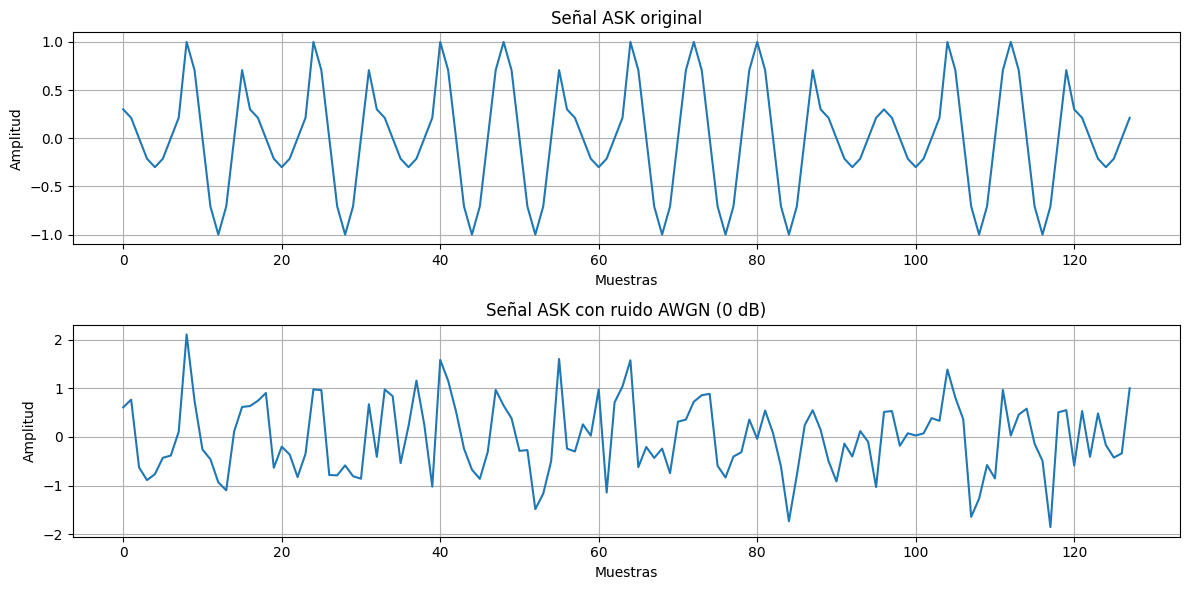

In [ ]:
# Generar una señal ASK original
senal_original = generar_ASK()

# Crear una versión con ruido
senal_con_ruido = agregar_ruido_AWGN(
    senal_original, 0
)

# Graficar ambas señales
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(senal_original)
plt.title("Señal ASK original")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(senal_con_ruido)
plt.title("Señal ASK con ruido AWGN (0 dB)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print("Distribución de niveles SNR:\n")

for nivel in niveles_snr:

    cantidad = np.sum(snr_datos == nivel)

    print(nivel, "dB:", cantidad, "señales")

Distribución de niveles SNR:

-5 dB: 641 señales
0 dB: 663 señales
5 dB: 661 señales
10 dB: 674 señales
15 dB: 654 señales
20 dB: 707 señales


In [ ]:
# Separar datos para entrenamiento y prueba

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba, snr_entrenamiento, snr_prueba = train_test_split(
    X,
    y,
    snr_datos,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Separación de datos completada\n")

print("Datos de entrenamiento:", len(X_entrenamiento))
print("Etiquetas de entrenamiento:", len(y_entrenamiento))

print("Datos de prueba:", len(X_prueba))
print("Etiquetas de prueba:", len(y_prueba))

Separación de datos completada

Datos de entrenamiento: 3200
Etiquetas de entrenamiento: 3200
Datos de prueba: 800
Etiquetas de prueba: 800


In [ ]:
np.savez(
    "dataset_entrenamiento_prueba.npz",

    X_entrenamiento=X_entrenamiento,
    X_prueba=X_prueba,

    y_entrenamiento=y_entrenamiento,
    y_prueba=y_prueba,

    snr_entrenamiento=snr_entrenamiento,
    snr_prueba=snr_prueba
)

print("Datos de entrenamiento y prueba guardados correctamente.")

Datos de entrenamiento y prueba guardados correctamente.


Fase 2

Investigar arquitecturas CNN (Actividad 2.1)

Una CNN (Convolutional Neural Network), también conocida como red neuronal convolucional, es un tipo de inteligencia artificial que puede identificar características y patrones dentro de los datos.

En nuestro proyecto utilizaremos una arquitectura llamada 1D-CNN (Convolutional Neural Network 1D).

¿Por qué se utilizara una 1D-CNN?

Porque nuestras señales son secuencias de datos numéricos. Recuerda que cada señal que generamos en la primera fase tiene 128 muestras.

La red neuronal utilizará filtros convolucionales para detectar características como:
- Cambios de amplitud.
- Variaciones de frecuencia.
- Cambios de fase.
- Patrones que permitan diferenciar las modulaciones.
A diferencia de una CNN tradicional que trabaja con imágenes, una 1D-CNN analiza los datos a lo largo de una dimensión, por lo que resulta adecuada para trabajar con nuestras señales.

¿Cómo funcionará la red neuronal?

1. Recibirá una señal de 128 muestras.
2. Las capas convolucionales analizarán sus características.
3. La capa Flatten organizará los resultados.
4. Las capas Dense realizarán la clasificación.
5. La capa Softmax entregará una probabilidad para cada modulación.


Antes de diseñar nuestro modelo, necesitamos adaptar las señales para que TensorFlow pueda procesarlas.

En la primera fase nuestras señales tenían dimensiones de (4000, 128). Sin embargo, una capa Conv1D necesita recibir los datos con tres dimensiones:
- Cantidad de señales.
- Cantidad de muestras por señal.
- Número de canales.
Por eso convertiremos nuestros datos a (4000, 128, 1).

In [ ]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Preparar las señales
X_entrenamiento_CNN = X_entrenamiento.reshape(
    -1, 128, 1
)

X_prueba_CNN = X_prueba.reshape(
    -1, 128, 1
)

# Convertir las etiquetas de texto a números
codificador = LabelEncoder()

y_entrenamiento_num = codificador.fit_transform(
    y_entrenamiento
)

y_prueba_num = codificador.transform(
    y_prueba
)

# Convertir las etiquetas a formato categórico
y_entrenamiento_CNN = to_categorical(
    y_entrenamiento_num, num_classes=4
)

y_prueba_CNN = to_categorical(
    y_prueba_num, num_classes=4
)

print("Datos preparados correctamente")
print("Forma de entrenamiento:", X_entrenamiento_CNN.shape)
print("Forma de prueba:", X_prueba_CNN.shape)

print("Clases:", codificador.classes_)

Datos preparados correctamente
Forma de entrenamiento: (3200, 128, 1)
Forma de prueba: (800, 128, 1)
Clases: ['ASK' 'FSK' 'PSK' 'QAM']


In [ ]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Flatten,
    Dense
)

print("Capas de la red neuronal importadas correctamente")

Capas de la red neuronal importadas correctamente


In [ ]:
modelo = Sequential([

    # Capa de entrada
    Input(shape=(128, 1)),

    # Primera capa convolucional
    Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu'
    ),

    # Segunda capa convolucional
    Conv1D(
        filters=64,
        kernel_size=3,
        activation='relu'
    ),

    # Convertir características en un vector
    Flatten(),

    # Capa de salida: 4 modulaciones
    Dense(
        4,
        activation='softmax'
    )

])

print("Modelo CNN creado correctamente")

Modelo CNN creado correctamente


In [ ]:
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 126, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 124, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7936)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        31,748 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,084 (148.77 KB)

 Trainable params: 38,084 (148.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']

)

print("Modelo compilado correctamente")

Modelo compilado correctamente


In [ ]:
historial = modelo.fit(

    X_entrenamiento_CNN,

    y_entrenamiento_CNN,

    epochs=30,

    batch_size=32,

    validation_split=0.2,

    verbose=1

)

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.7563 - loss: 0.5749 - val_accuracy: 0.8500 - val_loss: 0.3233
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9312 - loss: 0.2011 - val_accuracy: 0.9469 - val_loss: 0.1646
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9812 - loss: 0.0879 - val_accuracy: 0.9578 - val_loss: 0.1375
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9840 - loss: 0.0586 - val_accuracy: 0.9547 - val_loss: 0.1255
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9906 - loss: 0.0370 - val_accuracy: 0.9578 - val_loss: 0.1375
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9953 - loss: 0.0232 - val_accuracy: 0.9563 - val_loss: 0.1356
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9996 - loss: 0.0105 - val_accuracy: 0.9625 - val_loss: 0.1425
Epoch 8/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 1.0000 - loss: 0.0065 - val_accuracy: 0.9563 - val_lo

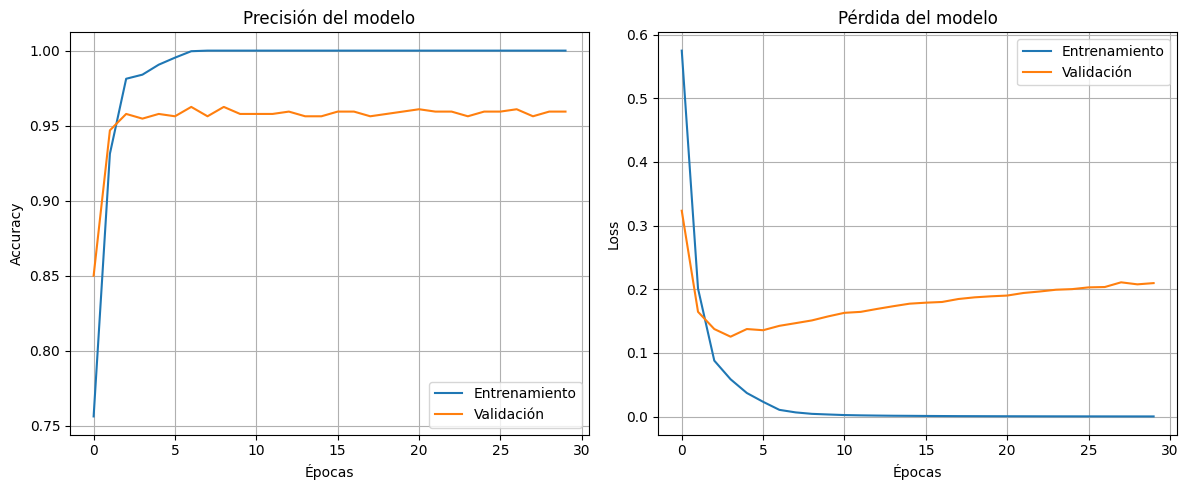

In [ ]:
plt.figure(figsize=(12, 5))

# Gráfica de precisión
plt.subplot(1, 2, 1)

plt.plot(historial.history['accuracy'],
         label='Entrenamiento')

plt.plot(historial.history['val_accuracy'],
         label='Validación')

plt.title('Precisión del modelo')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfica de pérdida
plt.subplot(1, 2, 2)

plt.plot(historial.history['loss'],
         label='Entrenamiento')

plt.plot(historial.history['val_loss'],
         label='Validación')

plt.title('Pérdida del modelo')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Guardar el modelo entrenado

modelo.save("detector_modulaciones.keras")

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


In [ ]:
# Guardar las clases del modelo

np.save(
    "etiquetas_modulaciones.npy",
    codificador.classes_
)

print("Etiquetas guardadas correctamente.")

Etiquetas guardadas correctamente.


In [ ]:
from google.colab import files

files.download("detector_modulaciones.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("etiquetas_modulaciones.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fase 3

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print("Herramientas de evaluación importadas correctamente")

Herramientas de evaluación importadas correctamente


In [ ]:
# Realizar predicciones
predicciones = modelo.predict(X_prueba_CNN)

# Obtener la clase con mayor probabilidad
y_pred = np.argmax(predicciones, axis=1)

# Obtener las respuestas reales
y_real = np.argmax(y_prueba_CNN, axis=1)

print("Predicciones realizadas correctamente")
print("Total de señales evaluadas:", len(y_pred))

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Predicciones realizadas correctamente
Total de señales evaluadas: 800


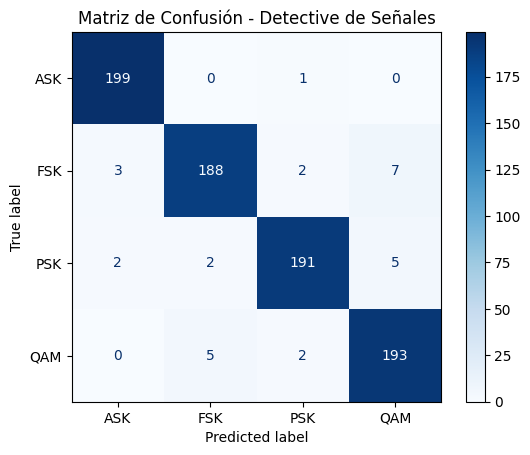

In [ ]:
# Crear matriz de confusión
matriz = confusion_matrix(
    y_real,
    y_pred
)

# Mostrar matriz
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=codificador.classes_
)

visualizacion.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusión - Detective de Señales")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

precision = accuracy_score(
    y_real,
    y_pred
)

print("Precisión general del modelo:")
print(f"{precision * 100:.2f}%")

Precisión general del modelo:
96.38%


In [ ]:
from sklearn.metrics import accuracy_score

# Definir grupos de ruido
grupos_snr = {
    "Ruido bajo (SNR -5 y 0 dB)": [-5, 0],
    "Ruido medio (SNR 5 y 10 dB)": [5, 10],
    "Ruido alto (SNR 15 y 20 dB)": [15, 20]
}

resultados_ruido = {}

# Evaluar cada grupo
for nombre, niveles in grupos_snr.items():

    # Seleccionar señales del grupo
    mascara = np.isin(snr_prueba, niveles)

    X_grupo = X_prueba_CNN[mascara]
    y_grupo = y_prueba_num[mascara]

    # Realizar predicciones
    predicciones_grupo = modelo.predict(
        X_grupo,
        verbose=0
    )

    y_pred_grupo = np.argmax(
        predicciones_grupo,
        axis=1
    )

    # Calcular precisión
    precision_grupo = accuracy_score(
        y_grupo,
        y_pred_grupo
    )

    resultados_ruido[nombre] = precision_grupo * 100

    print(nombre)
    print("Señales evaluadas:", len(X_grupo))
    print(f"Precisión: {precision_grupo * 100:.2f}%")
    print("-----------------------------")

Ruido bajo (SNR -5 y 0 dB)
Señales evaluadas: 246
Precisión: 88.62%
-----------------------------
Ruido medio (SNR 5 y 10 dB)
Señales evaluadas: 271
Precisión: 99.63%
-----------------------------
Ruido alto (SNR 15 y 20 dB)
Señales evaluadas: 283
Precisión: 100.00%
-----------------------------


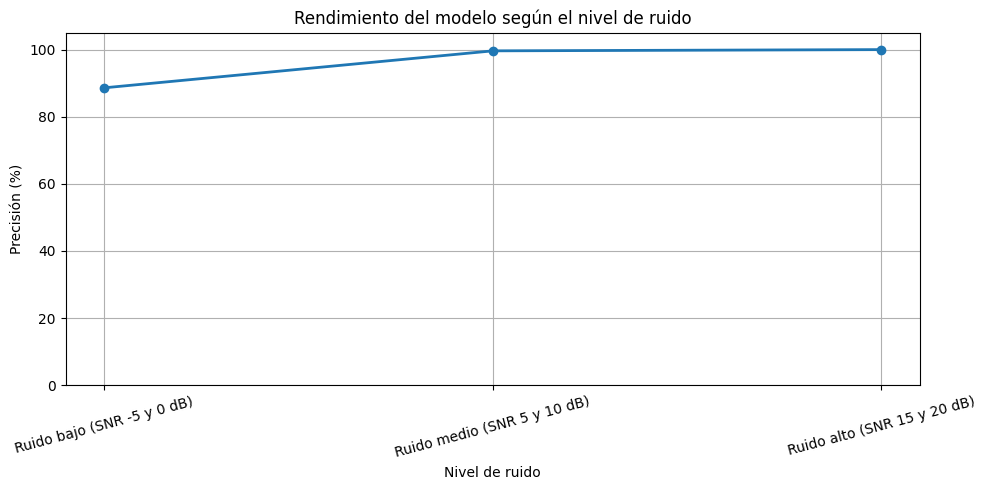

In [ ]:
nombres = list(resultados_ruido.keys())

precisiones = list(resultados_ruido.values())

plt.figure(figsize=(10, 5))

plt.plot(
    nombres,
    precisiones,
    marker='o',
    linewidth=2
)

plt.title("Rendimiento del modelo según el nivel de ruido")
plt.xlabel("Nivel de ruido")
plt.ylabel("Precisión (%)")

plt.ylim(0, 105)
plt.grid(True)

plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_real,
    y_pred,
    target_names=codificador.classes_
))

              precision    recall  f1-score   support

         ASK       0.98      0.99      0.99       200
         FSK       0.96      0.94      0.95       200
         PSK       0.97      0.95      0.96       200
         QAM       0.94      0.96      0.95       200

    accuracy                           0.96       800
   macro avg       0.96      0.96      0.96       800
weighted avg       0.96      0.96      0.96       800



In [ ]:
errores = matriz.sum(axis=1) - np.diag(matriz)

for nombre, cantidad in zip(
    codificador.classes_,
    errores
):
    print(nombre, ":", cantidad, "errores")

print("\nModulación más difícil:",
      codificador.classes_[np.argmax(errores)])

ASK : 1 errores
FSK : 12 errores
PSK : 9 errores
QAM : 7 errores

Modulación más difícil: FSK
